# Надёжность заёмщиков

## Содержание

- [Описание](#section-1)
- [Импорт библиотек Python](#section-2)
- [Загрузка данных](#section-3)
- [Предобработка данных](#section-4)
- [Исследовательский анализ данных](#section-5)
- [Общий вывод](#section-6)

<a id="section-1"></a>

## Описание

На исследовании находятся данные, предоставленные `крупным коммерческим банком` - **статистика о платёжеспособности клиентов**.

---

**Задача**

Разобраться, влияет ли семейное положение и количество детей клиента на факт погашения кредита в срок.

Сформировать ответ на вопросы, интересующие руководство банка:

* Есть ли зависимость между количеством детей и возвратом кредита в срок;
* Есть ли зависимость между семейным положением и возвратом кредита в срок;
* Есть ли зависимость между уровнем дохода и возвратом кредита в срок;
* Как разные цели кредита влияют на его возврат в срок.

---

**Описание данных**

* **children** - количество детей в семье;
* **days_employed** - общий трудовой стаж в днях;
* **dob_years** - возраст клиента в годах;
* **education** - уровень образования клиента;
* **education_id** - идентификатор уровня образования;
* **family_status** - семейное положение;
* **family_status_id** - идентификатор семейного положения;
* **gender** - пол клиента;
* **income_type** - тип занятости;
* **debt** - имел ли задолженность по возврату кредитов;
* **total_income** - ежемесячный доход;
* **purpose** - цель получения кредита.

<a id="section-2"></a>

## Импорт библиотек Python

Данный этап характеризуется следующими последовательными действиями:

1. Импорт библиотек Python для работы над проектом в части:
  * работа с табличными данными:
    * numpy;
    * pandas.
  * визуализация данных:
    * matplotlib;
    * seaborn.
2. Инициализация констант для работы с проектом;
3. Формирование вывода по итогам данного этапа.

In [1]:
# импорт библиотек Python

## работа с табличными данными
## визуализация данных
import os
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
# инициализация переменных проекта

DIR_PATH = os.getcwd()
DATA_DIR = os.environ.get('PORTFOLIO_DATA_DIR', '../data/raw')
DATA_NAME = 'data.csv'

# сборка пути к данным
DATA_PATH = os.path.join(DIR_PATH, DATA_DIR, DATA_NAME)

In [3]:
# установки настроек визуализации для всего проекта
plt.rcParams['figure.figsize'] = (12, 5)

**Вывод**

1. Импортированы библиотеки Python для работы над проектом в части:
  * работы с табличными данными:
    * numpy;
    * pandas.
  * визуализации данных:
    * matplotlib;
    * seaborn.
2. Инициализированы константы для работы с проектом:
  * **DIR_PATH** - текущая рабочая директория;
  * **DATA_DIR** - директория с хранимыми данными;
  * **DATA_NAME** - название исходного набора данных.

<a id="section-3"></a>

## Загрузка данных

Данный этап характеризуется следующими последовательными действиями:

1. Загрузка набора данных в рабочую среду Jupyter Notebook - инициализирована переменной `data`;
2. инициализирована пользовательских функций предварительного обзора набора данных;
3. Вывод на экран основной информации о наборе данных для формирования плана последующих действий;
4. Формирование вывода по итогам данного этапа.

In [4]:
# загрузка данных в рабочую среду
data = pd.read_csv(DATA_PATH)

In [5]:
# инициализирована пользовательской функции просмотра пропущенных значений
def na_statistics(df : pd.DataFrame) -> None:
    df_na = df.isna().sum().to_frame()
    df_na.columns = ['na_count']
    df_na['na_share'] = round(df_na['na_count'] / df.shape[0] * 100.0, 2)
    print('Пропущенные значения в наборе данных')
    display(df_na)

In [6]:
# инициализирована пользовательской функции просмотра названий признаков и типов данных
def feature_info(df : pd.DataFrame) -> None:
    df_features = df.dtypes.to_frame()
    df_features.columns = ['feature_type']
    print('Названия признаков набора данных и их типы')
    display(df_features)

In [7]:
# инициализирована пользовательской функции построения распределений количественных непрерывных показателей
def num_distribution(column : str, bins : int):
    plt.subplot(1, 2, 1)
    plt.xlabel(f'Значения признака \n{column}')
    plt.ylabel('Частота значений признака')
    plt.title(f'Гистограмма значений \n{column}', fontsize = 10)
    sns.histplot(data = data, x = data[column], bins = bins)
    plt.subplot(1, 2, 2)
    plt.xlabel(f'Значения признака \n{column}')
    plt.title(f'Диаграмма размаха значений \n{column}', fontsize = 10)
    sns.boxplot(data = data, x = data[column])
    plt.grid(False)
    plt.show()

In [8]:
# инициализация пользовательской функции построения распределений количественных дискретных показателей
def discr_distribution(column : str):
    ax = (
        sns.countplot(
            data = data,
            x = column,
            stat='count'
        )
    )

    ax.set(
        xlabel = f'Значения признака {column}',
        ylabel = 'Количество значений по признаку',
        title = f'Распределение значнений по признаку {column}'
    )
    plt.xticks(rotation = 45)
    plt.show()

In [9]:
# вывод на экран общей статистики по пропущенным значениям
na_statistics(data)

Пропущенные значения в наборе данных


,na_count,na_share
children,0,0.0
days_employed,2174,10.1
dob_years,0,0.0
education,0,0.0
education_id,0,0.0
family_status,0,0.0
family_status_id,0,0.0
gender,0,0.0
income_type,0,0.0
debt,0,0.0


In [10]:
# вывод на экран информации по признакам и их типам
feature_info(data)

Названия признаков набора данных и их типы


,feature_type
children,int64
days_employed,float64
dob_years,int64
education,object
education_id,int64
family_status,object
family_status_id,int64
gender,object
income_type,object
debt,int64


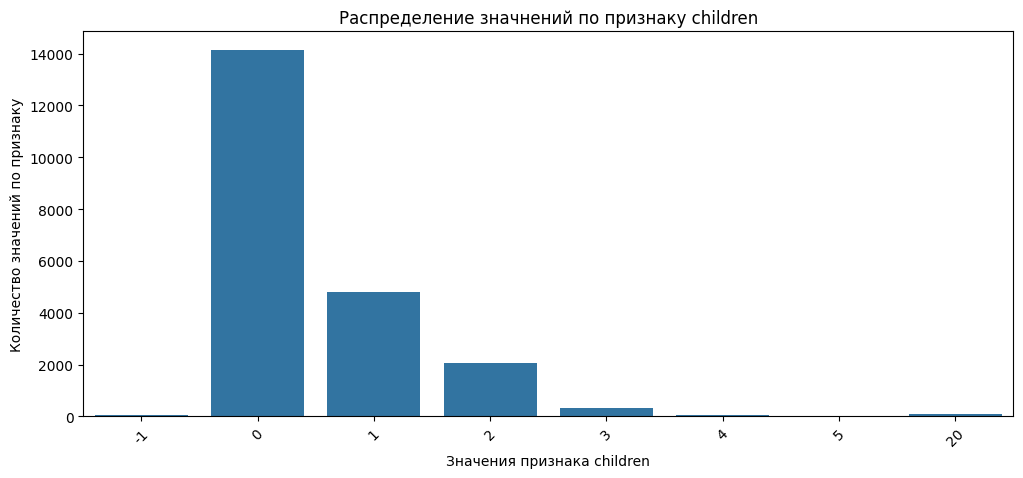

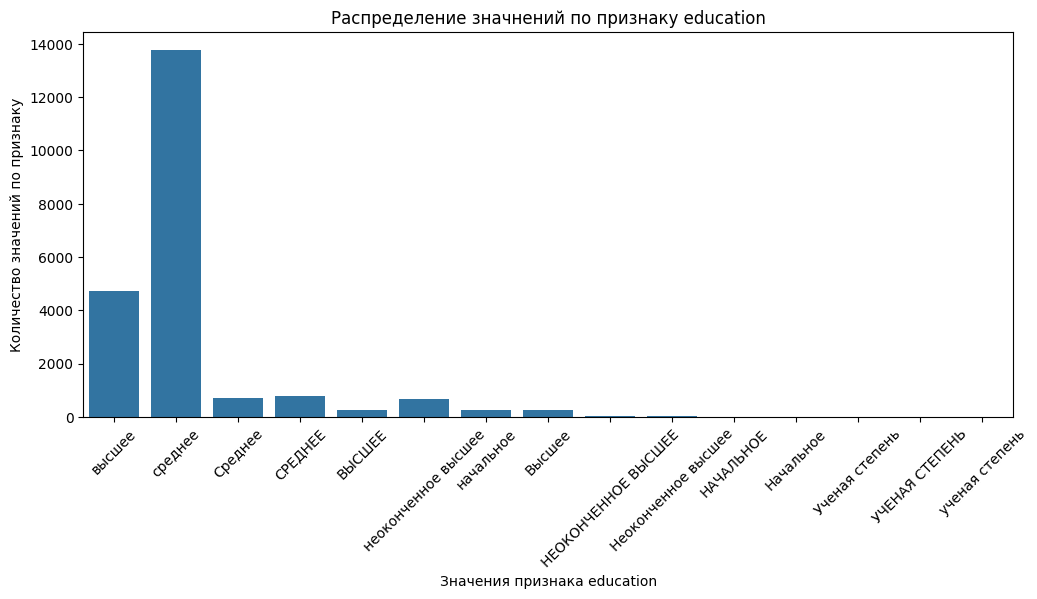

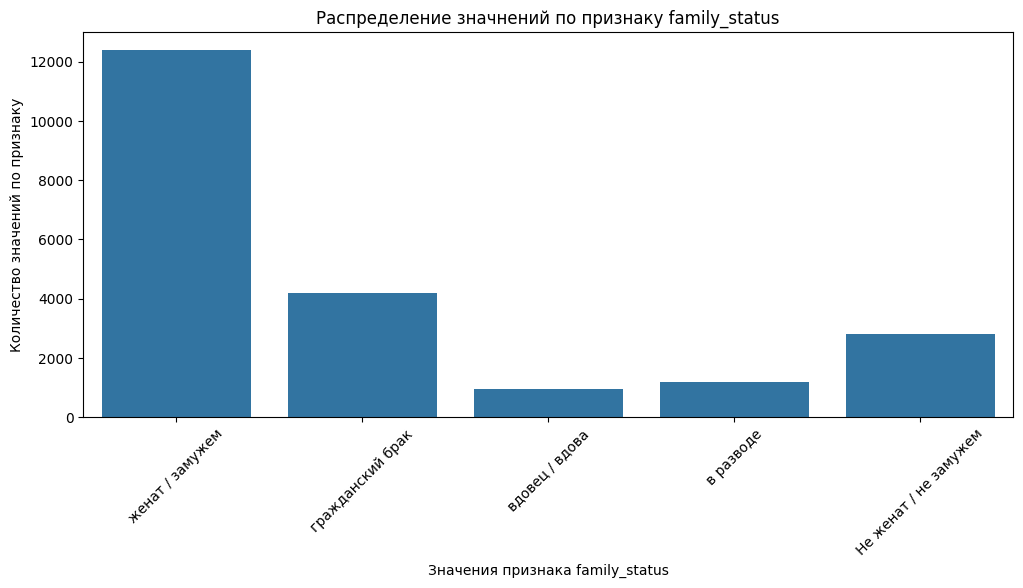

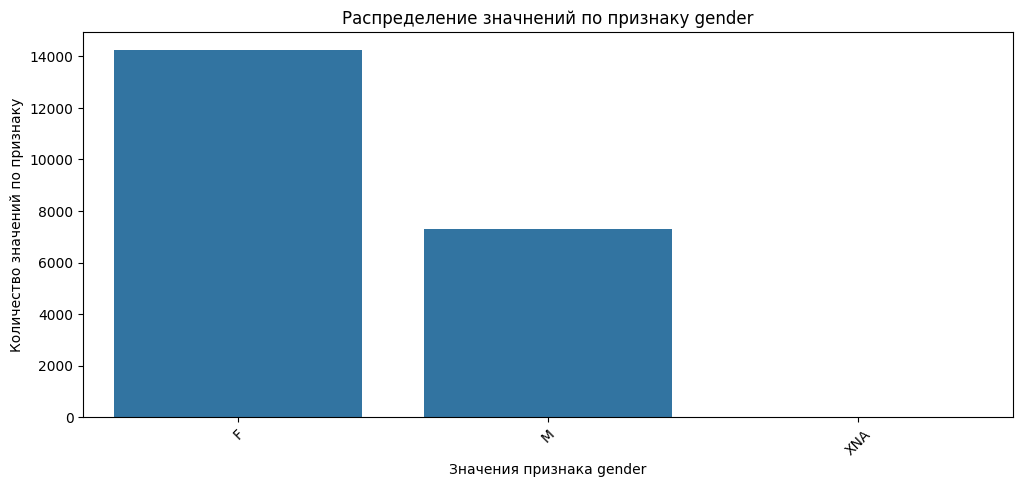

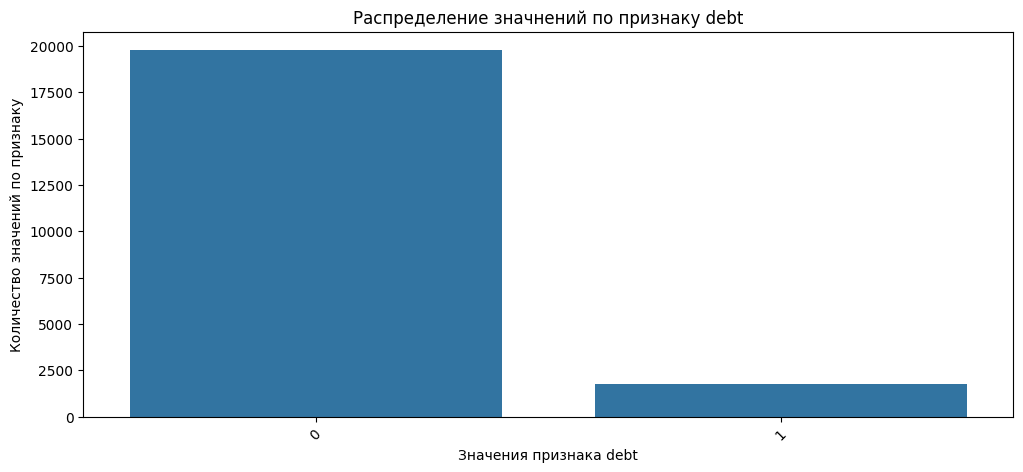

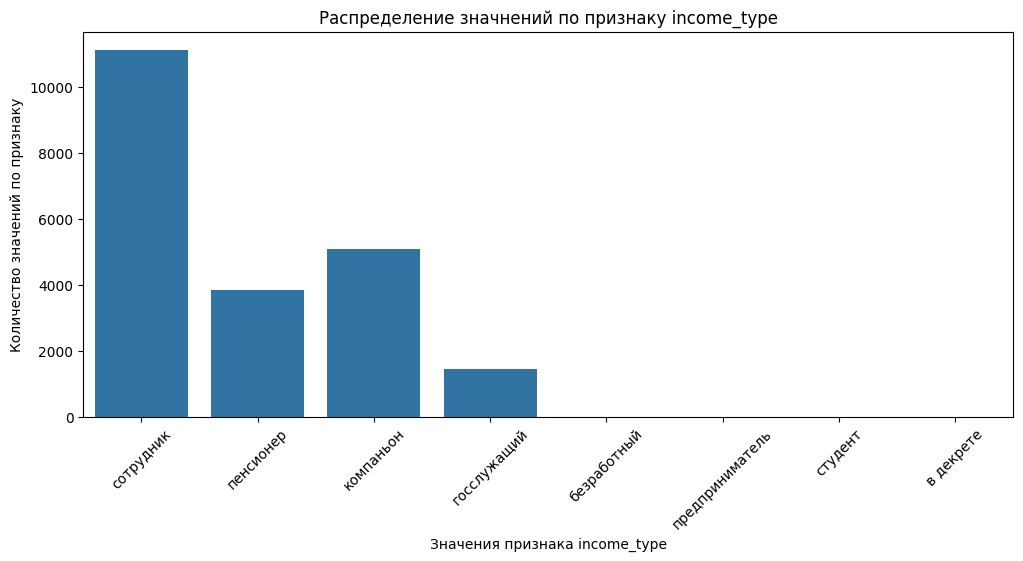

In [11]:
# построение визуализации дискретных количественных показателей
discr_features = ['children', 'education', 'family_status', 'gender', 'debt', 'income_type']

for feature in discr_features:
    discr_distribution(feature)

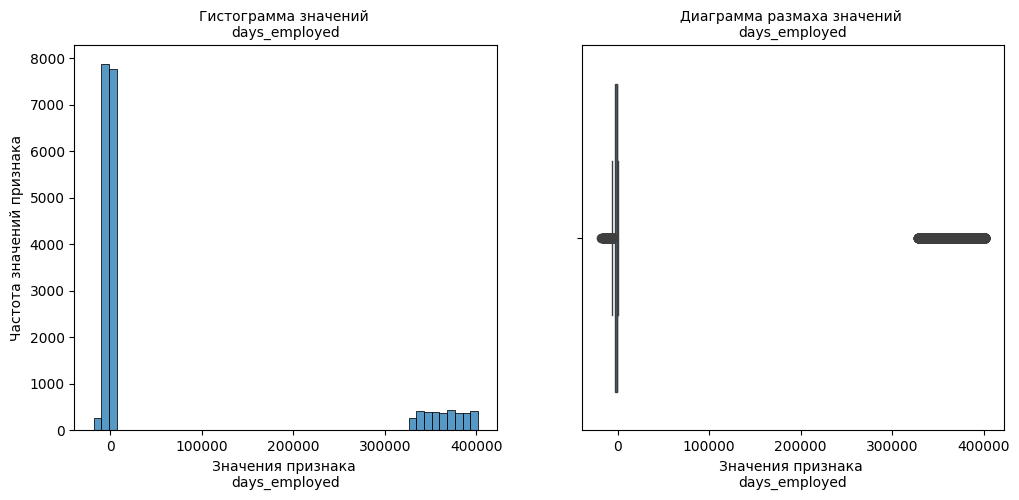

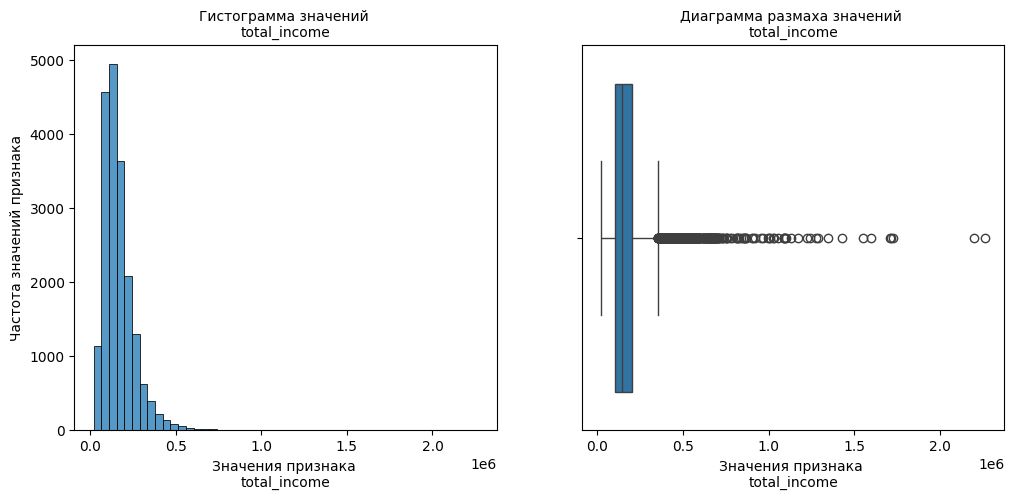

In [12]:
# построение визуализации непрерывных количественных показателей
num_features = ['days_employed', 'total_income']

for feature in num_features:
    num_distribution(feature, 50)

In [13]:
# вывод на экран информации о размере данных
print(f'Количество строк в наборе данных: {data.shape[0]}')
print(f'Количество столбцов в наборе данных: {data.shape[1]}')

Количество строк в наборе данных: 21525
Количество столбцов в наборе данных: 12


**Вывод**

1. Выполнена загрузка данных в рабочую среду - инициализирована переменная `data`;
2. Инициализированы пользовательские функции для просмотра первичной информации о наборе данных:
  * na_statistics - для просмотра пустых значений;
  * feature_info - для просмотра названий признаков набора данных и их типов;
  * num_distribution - для просмотра распределения количественных показателей (таких значений в наборе нет).
3. Выведена основная информация о наборе данных:
  * Количество строк - **21_525**, Количество столбцов - **12**;
  * Типы данных:
    * **children** - количество детей в семье - целочисленный;
    * **days_employed** - общий трудовой стаж в днях - число с плавающей точкой;
    * **dob_years** - возраст клиента в годах - целочисленный;
    * **education** - уровень образования клиента - строка;
    * **education_id** - идентификатор уровня образования - целочисленный;
    * **family_status** - семейное положение - строка;
    * **family_status_id** - идентификатор семейного положения - целочисленный;
    * **gender** - пол клиента - строка;
    * **income_type** - тип занятости - строка;
    * **debt** - имел ли задолженность по возврату кредитов - целочисленный;
    * **total_income** - ежемесячный доход - число с плавающей точкой;
    * **purpose** - цель получения кредита - строка.
  * **Нарушений форматирования snake_case** в названиях признаков не наблюдается;
  * **Имеются пропущенные значения по набору данных**:
    * **days_employed**;
    * **total_income**;
    * Также есть пустые значения в признаке **gender** (вероятно ошибка в типе данных);
  * **Обнаружены отрицательные значения по признакам**:
    * **children**;
    * **days_employed**.
  * **Обнаружены аномально большие значения по признакам**:
    * **days_employed**;
    * **total_income**.
  * **Обнаружены неявные дубликаты** по признаку **education**;
  * **Есть дублирование признаков по семантике**:
    * education и education_id;
    * family_status и family_status_id.

<a id="section-4"></a>

## Предобработка данных

Данный этап характеризуется следующими последовательными действиями:

1. Замена пропущенных значений по набору данных:
    * **total_income**;
    * **days_employed**;
    * **gender**.
2. Проверка набора данных на дубликаты (явные и неявные);
3. Проверка набора данных на аномальные значения и принятие решений об их устранении;
4. Преобразование типов данных с учетом семантики значений в столбце;
5. Формирование вывода по итогам данного этапа.

In [14]:
# пользовательская функция обработки строковых значений по набору данных
def string_preparation(column : pd.Series) -> pd.Series:
    return (
        column.str.strip()
        .str.lower()
        .str.replace(' ', '_')
    )

# обработка неявных дубликатов по категориальным строковым признакам
for col in ['education', 'family_status', 'income_type', 'purpose']:
    data[col] = string_preparation(data[col])

In [15]:
# проверка совпадения пропущенных значений по строкам для признаков 'total_income' и 'days_employed'
data[(data['total_income'].isna() == True) & (data['days_employed'].isna() == True)].shape[0]

2174

**Вывод по промежуточному этапу**

Обнаружено полное совпадение количества строк с пропущенными значениями по признакам **total_income** и **days_employed**

Вероятнее всего данная информация приведена по сотрудникам, которые только устроились на работу и у них не зафиксирован трудовой стаж и сумма доходов.

**Принятое решение**

Заполнить медианным значением приведенные показатели. Эта статистика - лучшее решение в данном случае.
Исключать 10% записей от исходного набора нельзя.

Заполнение произвести, опираясь на признак **income_type** - определенная профессиональная группа клиента.

In [16]:
# заполнение пустых значений с учетом профессиональной группы клиента

# инициализация пользовательской функции заполнения значений в зависимости от группы
def fillna_by_group(df : pd.DataFrame, na_column : str, group_column : str, function : str) -> pd.Series:
    return (
        df[na_column].fillna(
            df.groupby(group_column)[na_column]
            .transform(function)
        )
    )

In [17]:
# заполнение пустот по группам
data['total_income'] = fillna_by_group(data, 'total_income', 'income_type', 'median')
data['days_employed'] = fillna_by_group(data, 'days_employed', 'income_type', 'median')

# проверка наличия пустот в наборе данных
na_statistics(data)

Пропущенные значения в наборе данных


,na_count,na_share
children,0,0.0
days_employed,0,0.0
dob_years,0,0.0
education,0,0.0
education_id,0,0.0
family_status,0,0.0
family_status_id,0,0.0
gender,0,0.0
income_type,0,0.0
debt,0,0.0


In [18]:
# преобразование значений в признаке 'gender'
gender_map = {
    'M' : 1,
    'F' : 0
}

# исключение из набора данных строки со значением XNA
data = data.loc[data['gender'].isin(['M', 'F'])].copy()

data['gender'] = (
    pd.to_numeric(
        data['gender'].replace(gender_map)
    ).astype(int)
)

In [19]:
# проверка набора данных на наличие полных дубликатов
print(f'Количество полных дубликатов в наборе: {int(data.duplicated().sum())}')
print(f'Доля полных дубликатов в наборе: {float(data.duplicated().sum() / data.shape[0]):.2%}')

Количество полных дубликатов в наборе: 71
Доля полных дубликатов в наборе: 0.33%


In [20]:
# исключение полных дубликатов из набора данных
data = data.drop_duplicates().reset_index(drop=True)

In [21]:
# замена типов данных на соответствующие семантике значений
data['days_employed'] = data['days_employed'].astype(int)
data['total_income'] = data['total_income'].astype(int)

In [22]:
# проверка набора данных на аномальные значения

# проверка столбца 'children' на аномалии
print(f'Количество записей с отрицательными значениями: {(data["children"] < 0).sum()}')
print(f'Количество записей аномально большими значениями: {(data["children"] > 5).sum()}')

Количество записей с отрицательными значениями: 47
Количество записей аномально большими значениями: 76


**Вывод по промежуточному этапу**

На фоне общего количества записей в наборе данных подобное количество строк с аномальными значениями выглядит несущественным - **от них можно смело избавиться**.

Однако, можно выдвинуть гипотезу о том, что отрицательные значения по данному признаку появились в следствие технической ошибки (или человеческий фактор) внесения данных.

**Принятое решение**

Отрицательные значения преобразовать к положительным; Аномально большие - исключить.

In [23]:
# преобразование отрицательных значений признака 'children'
data['children'] = abs(data['children'])

# исключение из набора данных аномально больших значений по признаку 'children'
data = data.loc[data['children'] <= 5]

In [24]:
# проверка набора данных на аномальные значения

# проверка столбца 'days_employed' на аномалии
print(f'Количество записей с отрицательными значениями: {(data["days_employed"] < 0).sum()}')

Количество записей с отрицательными значениями: 17555


In [25]:
# преобразование отрицательных значений признака 'days_employed'
data['days_employed'] = abs(data['days_employed'])

**Вывод по промежуточному этапу**

Признак **days_employed** на текущий момент также характеризуется аномально большими значениями. Сотни тысяч дней соответствуют сотням лет.
Вероятно, что сами значения имеют неверный формат записи - их могли внести в часах.

**Принятое решение**

Принимается верхняя граница трудового стажа россиянина до выхода на пенсию - 55 лет. Выше этой границы значения из набора данных исключаются.

In [26]:
# фильтрация набора данных по признаку 'days_employed' - исключение аномально больших значений из набора
data['days_employed'] = (
    np.where(
        data['days_employed'] > 55 * 365, data['days_employed'] / 24, data['days_employed']
    )
)

**Вывод**

1. Проведена замена пропущенных значений по набору данных:
    * **total_income** - заполнено медианным значением по группам;
    * **days_employed** - заполнено медианным значением по группам;
    * **gender** - исключено пропущенное значение.
2. Проверка набора данных на дубликаты (явные и неявные):
    * Полные явные дубликаты исключены из набора данных - удалены строки;
    * Неявные дубликаты прошли преобразование и исключены из набора - с сохранением строк.
3. Проверка набора данных на аномальные значения и принятие решений об их устранении:
    * **children** - отрицательные значения преобразованы к положительным; Исключены из набора данных аномально большие значения;
    * **days_employed** - отрицательные значения преобразованы к положительным; Исключены из набора данных аномально большие значения;
4. Преобразование типов данных с учетом семантики значений в столбце:
    * **total_income** - целочисленный тип данных;
    * **days_employed** - целочисленный тип данных;
    * **gender** - целочисленный тип данных

<a id="section-5"></a>

## Исследовательский анализ данных

Данный этап характеризуется следующими последовательными действиями:

1. Подготовка двух новых датафреймов с комбинациями уникальных значений:
    * **education** и **education_id** - инициализация переменной `data_education`;
    * **family_status** и **family_status_id** - инициализация переменной `data_family`;
2. Исключение признаков **education** и **family_status** из исходного набора данных - перезапись переменной `data`;
3. Инициализация пользовательских функций добавления новых признаков в набор данных - перезапись переменной `data`;
4. Вывод на экран основной статистической информации о наборе данных;
5. Анализ количественных и категориальных показателей набора данных. Сформировать ответ на вопросы:
    * Есть ли зависимость между количеством детей и возвратом кредита в срок;
    * Есть ли зависимость между семейным положением и возвратом кредита в срок;
    * Есть ли зависимость между уровнем дохода и возвратом кредита в срок;
    * Как разные цели кредита влияют на его возврат в срок.
6. Формирование вывода по итогам данного этапа.

In [27]:
# формирование фреймов данных, содержащих уникальные комбинации строковых значений и их идентификаторов

data_education = (
    data[['education_id', 'education']]
    .drop_duplicates()
    .reset_index(drop = True)
)

data_family = (
    data[['family_status_id', 'family_status']]
    .drop_duplicates()
    .reset_index(drop = True)
)

In [28]:
# исключение из исходного набора данных признаков 'family_status' и 'education'
data = data.drop(['education', 'family_status'], axis = 1)

In [29]:
# инициализация пользовательской функции формирования категорий в зависимости от уровня дохода
def income_category(value):
    if value < 30_001:
        return 'E'
    elif value < 50_001:
        return 'D'
    elif value < 200_001:
        return 'C'
    elif value < 1_000_001:
        return 'B'
    else:
        return 'A'

In [30]:
# формирование нового столбца 'total_income_category'
data['total_income_category'] = data['total_income'].apply(income_category)

In [31]:
# инициализация пользовательской функции категоризации целей кредита
def purpose_categorise(value):
    if any(word in value for word in ['авто', 'трансп', 'машин']):
        return 'операции с автомобилем'
    elif any(word in value for word in ['женит', 'свадь', 'помолв']):
        return 'проведение свадьбы'
    elif any(word in value for word in ['дом', 'недвиж', 'кварт', 'комнат', 'жиль']):
        return 'операции с недвижимостью'
    elif any(word in value for word in ['образов', 'обуч', 'универ', 'школ', 'курс']):
        return 'получение образования'
    else:
        return np.nan

In [32]:
# формирование нового столбца 'purpose_category'
data['purpose_category'] = data['purpose'].apply(purpose_categorise)

In [33]:
# проверка выполнения категоризации
data['purpose_category'].value_counts(dropna=False)

purpose_category
операции с недвижимостью    10774
операции с автомобилем       4290
получение образования        3998
проведение свадьбы           2315
Name: count, dtype: int64

In [34]:
# вывод на экран основной информации о наборе данных - количественные показатели
print('Вывод на экран статистической информации по количественным показателям')
data.describe(include = 'number').T

Вывод на экран статистической информации по количественным показателям


,count,mean,std,min,25%,50%,75%,max
children,21377.0,0.475184,0.751965,0.0,0.0,0.0,1.0,5.0
days_employed,21377.0,4596.390517,5350.443984,24.0,1024.0,1997.0,5336.0,18388.0
dob_years,21377.0,43.277307,12.572157,0.0,33.0,42.0,53.0,75.0
education_id,21377.0,0.816953,0.549000,0.0,1.0,1.0,1.0,4.0
family_status_id,21377.0,0.974459,1.421802,0.0,0.0,0.0,1.0,4.0
gender,21377.0,0.339150,0.473432,0.0,0.0,0.0,1.0,1.0
debt,21377.0,0.081068,0.272947,0.0,0.0,0.0,0.0,1.0
total_income,21377.0,165314.386022,98259.299832,20667.0,107523.0,142594.0,195785.0,2265604.0


In [35]:
# вывод на экран основной информации о наборе данных - категориальные показатели
print('Вывод на экран статистической информации по количественным показателям')
data.describe(include = 'object').T

Вывод на экран статистической информации по количественным показателям


,count,unique,top,freq
income_type,21377,8,сотрудник,11041
purpose,21377,38,свадьба,790
total_income_category,21377,5,C,15959
purpose_category,21377,4,операции с недвижимостью,10774


Напишем функцию которая принимает список столбцов (или 1 столбец) для анализа просрочки и выводит таблицу с колонками: принятые столбцы / а) кол-во невыплат / б) кол-во записей в категории / доля невыплат по категории - а) делим на б)

In [36]:
# инициализация пользовательской функции построения сводной таблицы с группировкой

def analyse_debt(group_column):
    analyse_table = (
        data
        .groupby(group_column)
        .agg(
            debt_count = ('debt', 'sum'),
            total_clients = ('debt', 'count'),
        )
    )

    analyse_table['debt_share, %'] = (
        analyse_table['debt_count'] 
        / analyse_table['total_clients'] * 100).round(2)
    
    display(analyse_table)


    plot_data = (
        analyse_table[['debt_count', 'total_clients']]
        .reset_index()
        .melt(
            id_vars = group_column,
            value_vars=['debt_count', 'total_clients'],
            var_name='feature',
            value_name='value'
        )
    )

    ax = sns.barplot(
        data = plot_data,
        x = group_column,
        y = 'value',
        hue = 'feature',
        errorbar=None
    )

    ax.set(
        xlabel = f'Признак: {group_column}',
        ylabel = 'Количество клиентов',
        title = 'Распределение клиентов по наличию задолженности'
    )
    plt.legend(title = 'Показатель')
    plt.xticks(rotation = 45)
    plt.tight_layout()

    plt.show()

,debt_count,total_clients,"debt_share, %"
children,,,
0,1063,14090,7.54
1,445,4855,9.17
2,194,2052,9.45
3,27,330,8.18
4,4,41,9.76
5,0,9,0.00


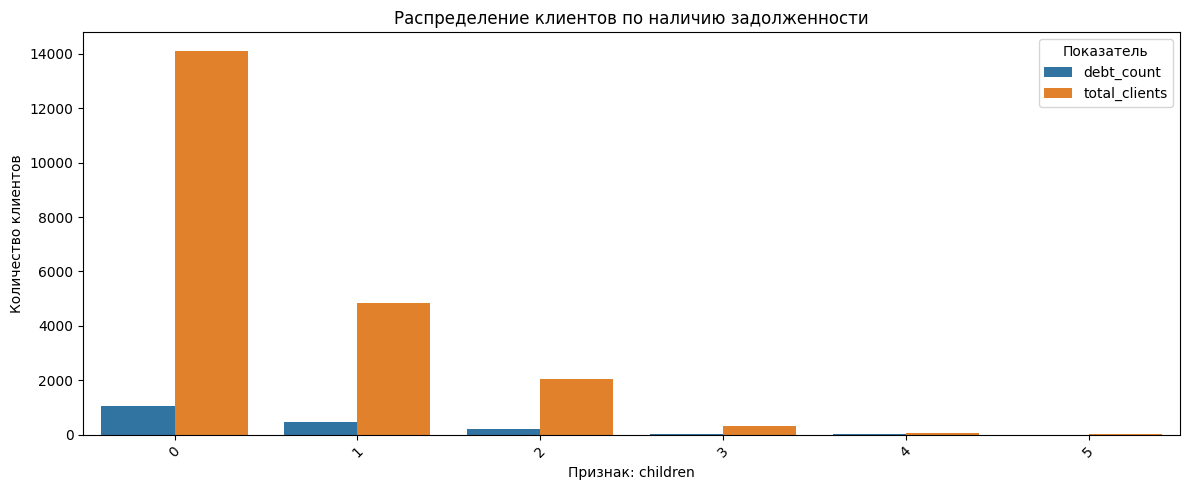

In [37]:
# вывод информации по признаку 'children'
analyse_debt('children')

**Вывод по промежуточному этапу**:

Заметная небольшая разница между клиентами, у которых нет детей, и клиентами, у которых есть хотя бы один ребенок - **возрастает процент клиентов с имеющимися задолженностями по кредитам**.

Можно так же отметить, что среди клиентов с детьми, минимальный процент должников - среди тех, у кого имеется 3 ребенка (возможно, что это связано с мерами государства по поддержке многодетных семей).

,family_status_id,family_status
0,0,женат_/_замужем
1,1,гражданский_брак
2,2,вдовец_/_вдова
3,3,в_разводе
4,4,не_женат_/_не_замужем


,debt_count,total_clients,"debt_share, %"
family_status_id,,,
0,928,12290,7.55
1,385,4138,9.30
2,63,955,6.60
3,84,1193,7.04
4,273,2801,9.75


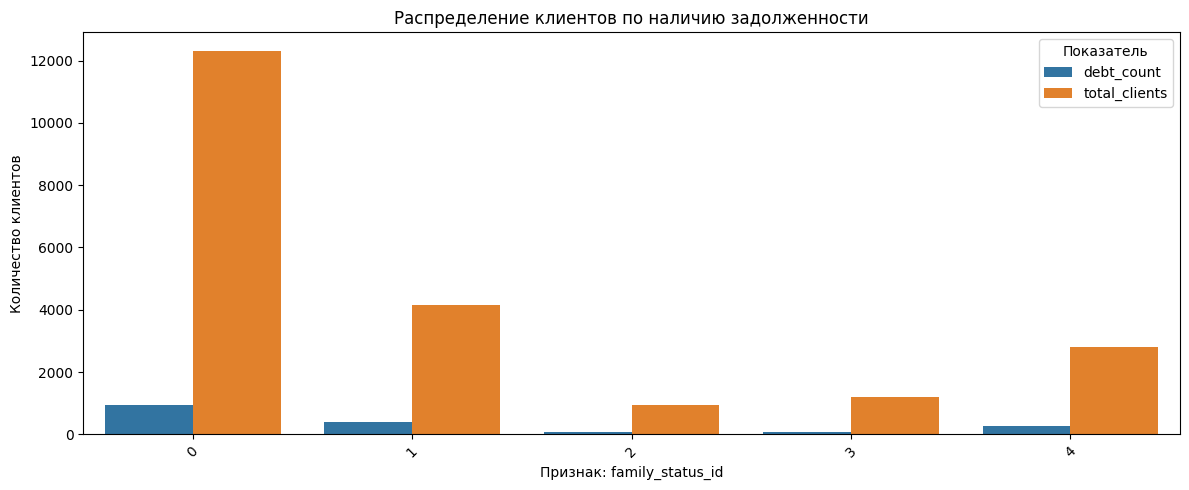

In [38]:
# вывод информации по признаку 'family_status_id'
display(data_family)

analyse_debt('family_status_id')

**Вывод по промежуточному этапу**:

Результат исследования показывает, что в группе клиентов со статусом не женат / не замужем доля должников больше всего - почти 9,8%.

Меньше всего должников среди вдовцов - 6,6%

,debt_count,total_clients,"debt_share, %"
total_income_category,,,
A,2,25,8.00
B,354,5021,7.05
C,1354,15959,8.48
D,21,350,6.00
E,2,22,9.09


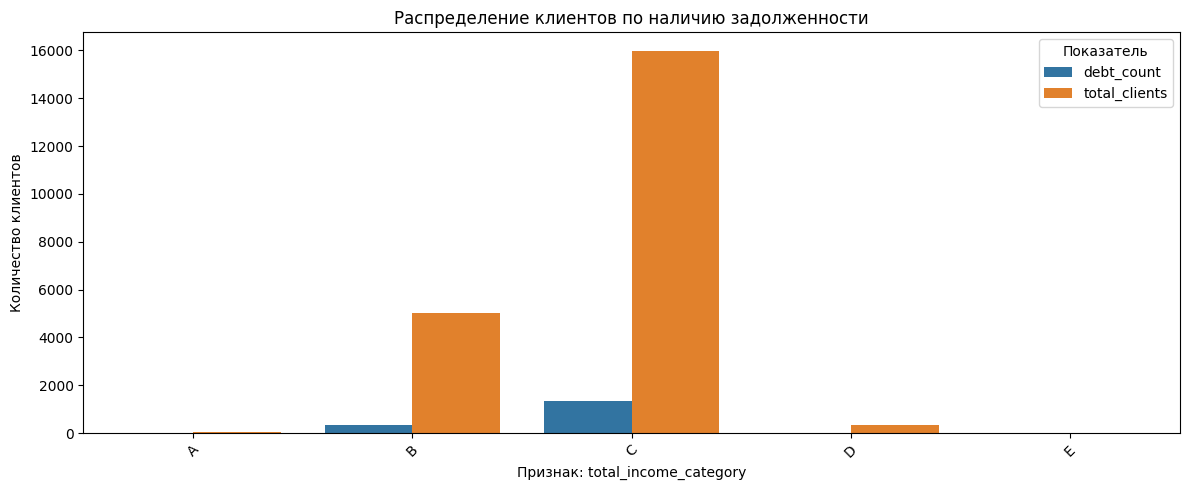

In [39]:
# вывод информации по признаку 'total_income_category'
analyse_debt('total_income_category')

**Вывод по промежуточному этапу**:

Количественно больше всего клиентов и должников в группе `C` по категоризации дохода. Относительный показатель должников тоже самый высокий - **8.5%**.

Самый высокий относительный показатель должников - в группе `E`. Однако выборка клиентов в данной группе совсем небольшая, и данные не репрезентативны.

##### Как разные цели кредита влияют на его возврат в срок?

,debt_count,total_clients,"debt_share, %"
purpose_category,,,
операции с автомобилем,401,4290,9.35
операции с недвижимостью,780,10774,7.24
получение образования,369,3998,9.23
проведение свадьбы,183,2315,7.90


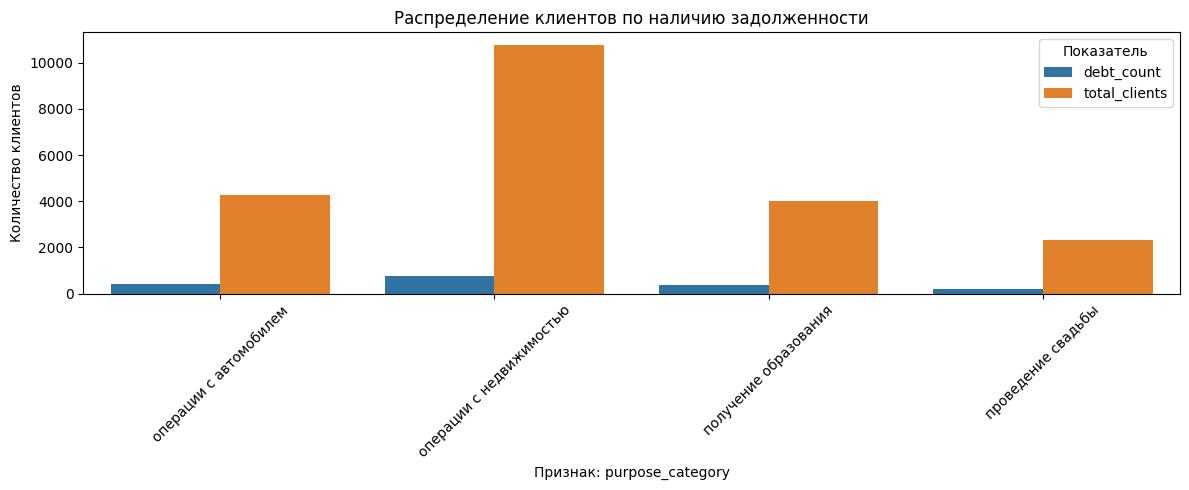

In [40]:
# вывод информации по признаку 'purpose_category'
analyse_debt('purpose_category')

**Вывод по промежуточному этапу**:

Высокий процент должников наблюдается в двух целях кредитования - `операции с автомобилем` и `получение образования` (9.35% и 9.23% соответственно)

**Вывод**

1. Выполнена подготовка двух новых датафреймов с комбинациями уникальных значений:
    * **education** и **education_id** - инициализирована переменная `data_education`;
    * **family_status** и **family_status_id** - инициализирована переменная `data_family`;
2. Исключены признаки **education** и **family_status** из исходного набора данных - перезапись переменной `data`;
3. Инициализированы пользовательские функций добавления новых признаков в набор данных:
    * **income_category** - категоризация уровней дохода;
    * **purpose_categorise** - категоризация причин взятия кредита.
4. Выведена на экран основная статистическая информация о наборе данных;
5. Проведен анализ количественных и категориальных показателей набора данных. Сформированы ответы на вопросы:
    * `Есть ли зависимость между количеством детей и возвратом кредита в срок`:
        * Заметная небольшая разница между клиентами, у которых нет детей, и клиентами, у которых есть хотя бы один ребенок - **возрастает процент клиентов с имеющимися задолженностями по кредитам**.
        * Можно так же отметить, что среди клиентов с детьми, минимальный процент должников - среди тех, у кого имеется 3 ребенка (возможно, что это связано с мерами государства по поддержке многодетных семей).
    * Есть ли зависимость между семейным положением и возвратом кредита в срок:
        * Результат исследования показывает, что в группе клиентов со статусом не женат / не замужем доля должников больше всего - почти 9,8%.
        * Меньше всего должников среди вдовцов - 6,6%
    * Есть ли зависимость между уровнем дохода и возвратом кредита в срок:
        * Количественно больше всего клиентов и должников в группе `C` по категоризации дохода. Относительный показатель должников тоже самый высокий - **8.5%**.
        * Самый высокий относительный показатель должников - в группе `E`. Однако выборка клиентов в данной группе совсем небольшая, и данные не репрезентативны.
    * Как разные цели кредита влияют на его возврат в срок:
        * Высокий процент должников наблюдается в двух целях кредитования - `операции с автомобилем` и `получение образования` (9.35% и 9.23% соответственно)

<a id="section-6"></a>

## Общий вывод:

1. Импортированы библиотеки Python для работы над проектом в части:
    * работы с табличными данными:
      * numpy;
      * pandas.
    * визуализации данных:
      * matplotlib;
      * seaborn.
2. Инициализированы константы для работы с проектом:
    * **DIR_PATH** - текущая рабочая директория;
    * **DATA_DIR** - директория с хранимыми данными;
    * **DATA_NAME** - название исходного набора данных.
3. Выполнена загрузка данных в рабочую среду - инициализирована переменная `data`;
4. Инициализированы пользовательские функции для просмотра первичной информации о наборе данных:
    * na_statistics - для просмотра пустых значений;
    * feature_info - для просмотра названий признаков набора данных и их типов;
    * num_distribution - для просмотра распределения количественных показателей (таких значений в наборе нет).
5. Выведена основная информация о наборе данных:
    * Количество строк - **21_525**, Количество столбцов - **12**;
    * Типы данных:
      * **children** - количество детей в семье - целочисленный;
      * **days_employed** - общий трудовой стаж в днях - число с плавающей точкой;
      * **dob_years** - возраст клиента в годах - целочисленный;
      * **education** - уровень образования клиента - строка;
      * **education_id** - идентификатор уровня образования - целочисленный;
      * **family_status** - семейное положение - строка;
      * **family_status_id** - идентификатор семейного положения - целочисленный;
      * **gender** - пол клиента - строка;
      * **income_type** - тип занятости - строка;
      * **debt** - имел ли задолженность по возврату кредитов - целочисленный;
      * **total_income** - ежемесячный доход - число с плавающей точкой;
      * **purpose** - цель получения кредита - строка.
    * **Нарушений форматирования snake_case** в названиях признаков не наблюдается;
    * **Имеются пропущенные значения по набору данных**:
      * **days_employed**;
      * **total_income**;
      * Также есть пустые значения в признаке **gender** (вероятно ошибка в типе данных);
    * **Обнаружены отрицательные значения по признакам**:
      * **children**;
      * **days_employed**.
    * **Обнаружены аномально большие значения по признакам**:
      * **days_employed**;
      * **total_income**.
    * **Обнаружены неявные дубликаты** по признаку **education**;
    * **Есть дублирование признаков по семантике**:
      * education и education_id;
      * family_status и family_status_id.
6. Проведена замена пропущенных значений по набору данных:
    * **total_income** - заполнено медианным значением по группам;
    * **days_employed** - заполнено медианным значением по группам;
    * **gender** - исключено пропущенное значение.
7. Проверка набора данных на дубликаты (явные и неявные):
    * Полные явные дубликаты исключены из набора данных - удалены строки;
    * Неявные дубликаты прошли преобразование и исключены из набора - с сохранением строк.
8. Проверка набора данных на аномальные значения и принятие решений об их устранении:
    * **children** - отрицательные значения преобразованы к положительным; Исключены из набора данных аномально большие значения;
    * **days_employed** - отрицательные значения преобразованы к положительным; Исключены из набора данных аномально большие значения;
9. Преобразование типов данных с учетом семантики значений в столбце:
    * **total_income** - целочисленный тип данных;
    * **days_employed** - целочисленный тип данных;
    * **gender** - целочисленный тип данных.
10. Выполнена подготовка двух новых датафреймов с комбинациями уникальных значений:
    * **education** и **education_id** - инициализирована переменная `data_education`;
    * **family_status** и **family_status_id** - инициализирована переменная `data_family`;
11. Исключены признаки **education** и **family_status** из исходного набора данных - перезапись переменной `data`;
12. Инициализированы пользовательские функций добавления новых признаков в набор данных:
    * **income_category** - категоризация уровней дохода;
    * **purpose_categorise** - категоризация причин взятия кредита.
13. Выведена на экран основная статистическая информация о наборе данных;
14. Проведен анализ количественных и категориальных показателей набора данных. Сформированы ответы на вопросы:
    * `Есть ли зависимость между количеством детей и возвратом кредита в срок`:
        * Заметная небольшая разница между клиентами, у которых нет детей, и клиентами, у которых есть хотя бы один ребенок - **возрастает процент клиентов с имеющимися задолженностями по кредитам**.
        * Можно так же отметить, что среди клиентов с детьми, минимальный процент должников - среди тех, у кого имеется 3 ребенка (возможно, что это связано с мерами государства по поддержке многодетных семей).
    * Есть ли зависимость между семейным положением и возвратом кредита в срок:
        * Результат исследования показывает, что в группе клиентов со статусом не женат / не замужем доля должников больше всего - почти 9,8%.
        * Меньше всего должников среди вдовцов - 6,6%
    * Есть ли зависимость между уровнем дохода и возвратом кредита в срок:
        * Количественно больше всего клиентов и должников в группе `C` по категоризации дохода. Относительный показатель должников тоже самый высокий - **8.5%**.
        * Самый высокий относительный показатель должников - в группе `E`. Однако выборка клиентов в данной группе совсем небольшая, и данные не репрезентативны.
    * Как разные цели кредита влияют на его возврат в срок:
        * Высокий процент должников наблюдается в двух целях кредитования - `операции с автомобилем` и `получение образования` (9.35% и 9.23% соответственно).

Таким образом, формируются портреты клиентов с максимальной вероятностью просрочки:

* имеет детей - в частности, клиенты с 4 детьми имеют самый высокий процент должников среди всей выборки;
* не женат/не замужем;
* берет кредит на операции с недвижимостью или на покупку автомобиля